# Process image folder

./faces


Action: emotion: 100%|██████████| 4/4 [00:00<00:00,  7.49it/s]


face.jpg
[{'age': 31, 'region': {'x': 166, 'y': 204, 'w': 698, 'h': 698, 'left_eye': (626, 484), 'right_eye': (375, 484)}, 'face_confidence': 0.89, 'gender': {'Woman': np.float32(99.95741), 'Man': np.float32(0.042591095)}, 'dominant_gender': 'Woman', 'race': {'asian': np.float32(97.81231), 'indian': np.float32(0.5659739), 'black': np.float32(0.0028638453), 'white': np.float32(0.11595354), 'middle eastern': np.float32(0.0014399604), 'latino hispanic': np.float32(1.5014493)}, 'dominant_race': 'asian', 'emotion': {'angry': np.float32(1.1949127e-08), 'disgust': np.float32(7.244299e-15), 'fear': np.float32(4.2096508e-07), 'happy': np.float32(97.775085), 'sad': np.float32(6.344615e-07), 'surprise': np.float32(0.00028946876), 'neutral': np.float32(2.224625)}, 'dominant_emotion': 'happy'}]


Action: emotion: 100%|██████████| 4/4 [00:00<00:00,  7.03it/s]


face2.jpg
[{'age': 34, 'region': {'x': 148, 'y': 213, 'w': 702, 'h': 702, 'left_eye': (624, 480), 'right_eye': (387, 485)}, 'face_confidence': 0.91, 'gender': {'Woman': np.float32(0.006197622), 'Man': np.float32(99.993805)}, 'dominant_gender': 'Man', 'race': {'asian': np.float32(2.8131214e-07), 'indian': np.float32(1.1639681e-07), 'black': np.float32(3.1263176e-09), 'white': np.float32(99.99192), 'middle eastern': np.float32(0.0042698705), 'latino hispanic': np.float32(0.0038153369)}, 'dominant_race': 'white', 'emotion': {'angry': np.float32(1.851343e-08), 'disgust': np.float32(3.4949524e-12), 'fear': np.float32(1.3482097e-06), 'happy': np.float32(99.99993), 'sad': np.float32(2.6329156e-08), 'surprise': np.float32(3.118373e-09), 'neutral': np.float32(7.485028e-05)}, 'dominant_emotion': 'happy'}]


Action: emotion: 100%|██████████| 4/4 [00:00<00:00,  7.00it/s]


happy.jpg
[{'age': 33, 'region': {'x': 115, 'y': 92, 'w': 173, 'h': 173, 'left_eye': (225, 154), 'right_eye': (170, 161)}, 'face_confidence': 0.95, 'gender': {'Woman': np.float32(1.3084428), 'Man': np.float32(98.69156)}, 'dominant_gender': 'Man', 'race': {'asian': np.float32(0.11433413), 'indian': np.float32(0.11557705), 'black': np.float32(0.004952755), 'white': np.float32(79.56094), 'middle eastern': np.float32(7.328908), 'latino hispanic': np.float32(12.875274)}, 'dominant_race': 'white', 'emotion': {'angry': np.float32(1.0823265e-16), 'disgust': np.float32(2.5553958e-28), 'fear': np.float32(6.2285516e-23), 'happy': np.float32(99.99975), 'sad': np.float32(1.3399222e-13), 'surprise': np.float32(9.25086e-15), 'neutral': np.float32(0.0002523443)}, 'dominant_emotion': 'happy'}]


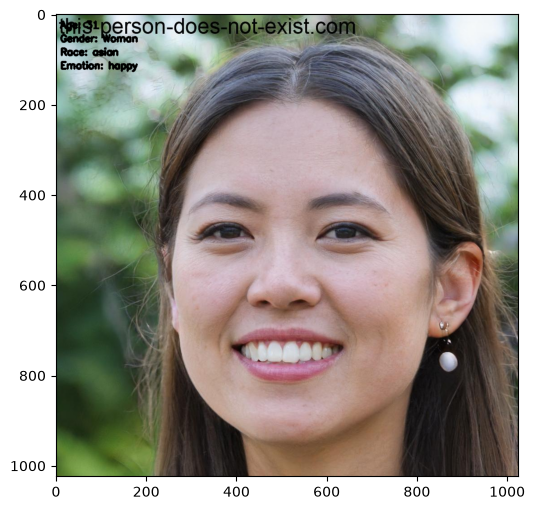

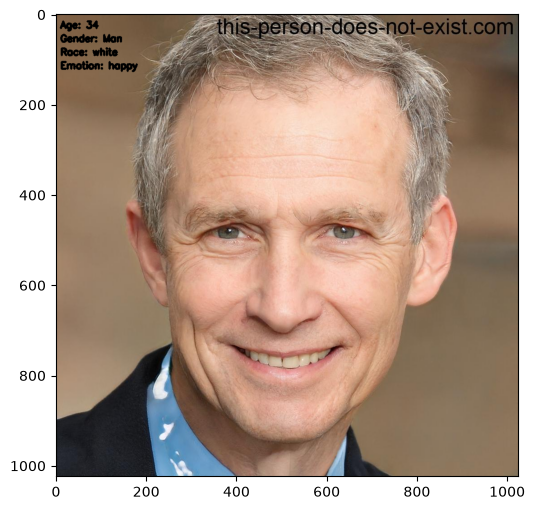

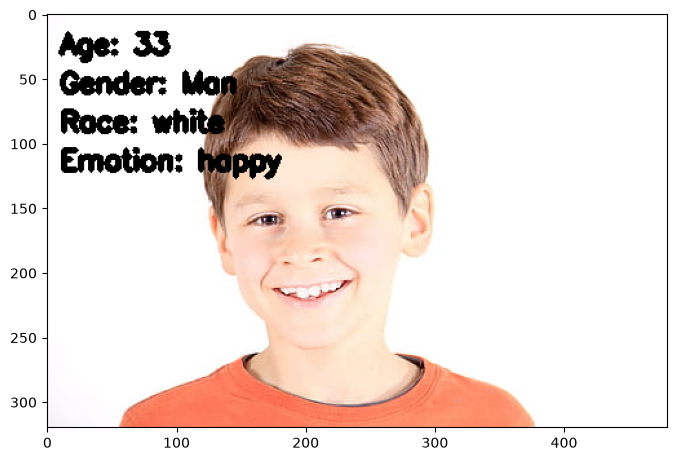

In [3]:
import os
import cv2
from deepface import DeepFace
import matplotlib.pyplot as plt

folder = './faces'

print(folder)

for file_name in os.listdir(folder):
    # Asume imágenes en formato png o jpg
    if file_name.endswith('.png') or file_name.endswith('.jpg'):
        # Procesa la imagen que asume hay cara, no fuerza la detección
        obj = DeepFace.analyze(img_path = os.path.join(folder, file_name), enforce_detection=False, actions =['age', 'gender', 'race', 'emotion'])
        print(file_name)
        print(obj)
        obj = obj[0]  # Accede al primer elemento de la lista devuelta por DeepFace.analyze
        #print the information in a plotting with the image
        plt.figure(figsize=(8, 6))
        img = cv2.imread(os.path.join(folder, file_name))
        
        cv2.putText(img, f"Age: {obj['age']}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 3)
        cv2.putText(img, f"Gender: {obj['dominant_gender']}", (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 3)
        cv2.putText(img, f"Race: {obj['dominant_race']}", (10, 90), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 3)
        cv2.putText(img, f"Emotion: {obj['dominant_emotion']}", (10, 120), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 3)
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        
        #print(obj["region"])
        #print(obj["age"])      
        #print(obj["gender"])      
        #print(obj["race"])       
        #print(obj["dominant_race"]) 
        #print(obj["emotion"])
        #print(obj["dominant_emotion"])
       
        


# Process from webcam

In [2]:
import cv2
from deepface import DeepFace

vid = cv2.VideoCapture(0)

# font 
font = cv2.FONT_HERSHEY_SIMPLEX
fontScale = 1
color = (255, 0, 0) 
thickness = 2 
pos = (50, 50) 
  
while(True):      
    # fotograma a fotograma
    ret, frame = vid.read()
  
    if ret:  
        obj = DeepFace.analyze(img_path = frame, enforce_detection=False, actions =['gender', 'emotion'])
        print(obj)

        # Primera cara
        image = cv2.putText(frame, str(obj[0]['dominant_gender']+' '+obj[0]['dominant_emotion']), pos, font,  
                        fontScale, color, thickness, cv2.LINE_AA) 
        # Muestra fotograma
        cv2.imshow('Vid', frame)
    
    # Detenemos pulsado ESC
    if cv2.waitKey(20) == 27:
        break
  
# Libera el objeto de captura
vid.release()
# Destruye ventanas
cv2.destroyAllWindows()

Action: emotion: 100%|██████████| 2/2 [00:00<00:00, 23.57it/s]


[{'gender': {'Woman': np.float32(0.33468044), 'Man': np.float32(99.66533)}, 'dominant_gender': 'Man', 'region': {'x': 134, 'y': 160, 'w': 276, 'h': 276, 'left_eye': (317, 269), 'right_eye': (222, 271)}, 'face_confidence': 0.97, 'emotion': {'angry': np.float32(7.1524846e-05), 'disgust': np.float32(1.3175495e-10), 'fear': np.float32(0.026641617), 'happy': np.float32(2.6224158), 'sad': np.float32(0.0014187827), 'surprise': np.float32(2.1969527e-05), 'neutral': np.float32(97.34943)}, 'dominant_emotion': 'neutral'}]


Action: emotion: 100%|██████████| 2/2 [00:00<00:00, 22.85it/s]


[{'gender': {'Woman': np.float32(0.5876014), 'Man': np.float32(99.4124)}, 'dominant_gender': 'Man', 'region': {'x': 135, 'y': 160, 'w': 274, 'h': 274, 'left_eye': (318, 269), 'right_eye': (221, 269)}, 'face_confidence': 0.96, 'emotion': {'angry': np.float32(0.011190478), 'disgust': np.float32(8.471767e-05), 'fear': np.float32(15.624024), 'happy': np.float32(73.79764), 'sad': np.float32(0.0091008665), 'surprise': np.float32(0.017632145), 'neutral': np.float32(10.540328)}, 'dominant_emotion': 'happy'}]


Action: emotion: 100%|██████████| 2/2 [00:00<00:00, 19.58it/s]


[{'gender': {'Woman': np.float32(17.484974), 'Man': np.float32(82.51502)}, 'dominant_gender': 'Man', 'region': {'x': 138, 'y': 160, 'w': 278, 'h': 278, 'left_eye': (319, 268), 'right_eye': (253, 374)}, 'face_confidence': 0.97, 'emotion': {'angry': np.float32(0.00023885143), 'disgust': np.float32(2.4174384e-12), 'fear': np.float32(0.10409937), 'happy': np.float32(0.0051100156), 'sad': np.float32(99.60752), 'surprise': np.float32(1.8023425e-09), 'neutral': np.float32(0.28303367)}, 'dominant_emotion': 'sad'}]


... (148 outputs left out)


Action: emotion: 100%|██████████| 2/2 [00:00<00:00, 25.58it/s]


[{'gender': {'Woman': np.float32(0.34408298), 'Man': np.float32(99.65592)}, 'dominant_gender': 'Man', 'region': {'x': 100, 'y': 162, 'w': 281, 'h': 281, 'left_eye': (272, 269), 'right_eye': (241, 270)}, 'face_confidence': 0.96, 'emotion': {'angry': np.float32(23.89532), 'disgust': np.float32(4.3316317), 'fear': np.float32(64.2172), 'happy': np.float32(0.10092786), 'sad': np.float32(5.610632), 'surprise': np.float32(0.094158955), 'neutral': np.float32(1.7501291)}, 'dominant_emotion': 'fear'}]


Action: emotion: 100%|██████████| 2/2 [00:00<00:00, 23.32it/s]


[{'gender': {'Woman': np.float32(0.53937614), 'Man': np.float32(99.46062)}, 'dominant_gender': 'Man', 'region': {'x': 103, 'y': 170, 'w': 261, 'h': 261, 'left_eye': (253, 271), 'right_eye': (178, 269)}, 'face_confidence': 0.97, 'emotion': {'angry': np.float32(40.592693), 'disgust': np.float32(0.16798899), 'fear': np.float32(26.332722), 'happy': np.float32(0.029245479), 'sad': np.float32(6.4271593), 'surprise': np.float32(5.837978), 'neutral': np.float32(20.612211)}, 'dominant_emotion': 'angry'}]
